# 03 Sensitivity

How much does the answer from notebook 02 depend on the uncertain inputs? Each point below is the optimal hybrid (solar, battery and a main generator all allowed), then run hour by hour with the no-foresight rule plus the clinic/school backup generator, exactly like the final design in notebook 02. Sweeps (`src/sensitivity.py`):

| Sweep | Values |
|---|---|
| Delivered diesel price | $0.50 to $3.00 per litre (today: about $2.68) |
| Li-ion battery cost | -30 %, median ($314/kWh), +30 % |
| ESMAP component costs | 25th percentile, median, 75th percentile for PV, battery and inverter together |
| Reliability target | households may go without 0 %, 1 % or 5 % of their energy |
| Demand growth | households +5 % a year for 5 years: size for today, or for year 5 |

All for the low clinic case; both household demand cases.

In [1]:
import sys
from pathlib import Path
import warnings; warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
FIG, PROC = ROOT / "figures", ROOT / "data" / "processed"
import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option("display.precision", 2); pd.set_option("display.max_columns", 30)
import sensitivity as se, costs as cst, demand as dm, solar

In [2]:
# Results are cached; delete data/processed/sensitivity*.parquet to recompute (~7 minutes).
f1, f2 = PROC / "sensitivity.parquet", PROC / "sensitivity_diesel_only.parquet"
if not (f1.exists() and f2.exists()):
    if not (PROC / "demand.parquet").exists():
        PROC.mkdir(parents=True, exist_ok=True); dm.build_all().to_parquet(PROC / "demand.parquet")
    if not (PROC / "pv_per_kwp.parquet").exists():
        solar.pv_per_kwp().to_frame().to_parquet(PROC / "pv_per_kwp.parquet")
    d = pd.read_parquet(PROC / "demand.parquet"); pv = pd.read_parquet(PROC / "pv_per_kwp.parquet")["pv_per_kwp"]
    res, dsl = se.run_all(d, pv); res["value"] = res["value"].astype(str)
    res.to_parquet(f1); dsl.to_parquet(f2)
res, dsl = pd.read_parquet(f1), pd.read_parquet(f2)
cols = ["PV kWp", "battery kWh", "main diesel kW", "backup generator kW", "households unserved %",
        "hours with household shortfall", "clinic/school hours cut", "diesel litres/yr", "LCOE delivered $/kWh", "LCOE delivered N/kWh"]

## 1. Diesel price: when does a generator come back?

In [3]:
ds = res[res.sweep == "diesel $/L"].assign(price=lambda x: x.value.astype(float))
ds.set_index(["demand", "price"])[cols]

PV kWp  battery kWh  main diesel kW  backup generator kW  \
demand price                                                             
low    0.50     9.60         0.00        1.16e+01                  3.0   
       0.75    44.43       129.19        7.53e-01                  3.0   
       1.00    48.31       131.89        3.39e-01                  3.0   
       1.25    51.59       132.69        1.04e-01                  3.0   
       1.50    53.39       133.22        7.19e-03                  3.0   
       2.00    53.54       133.28        0.00e+00                  3.0   
       2.68    53.54       133.28        0.00e+00                  3.0   
       3.00    53.54       133.28        0.00e+00                  3.0   
high   0.50    40.01         3.63        4.59e+01                  3.0   
       0.75   181.76       548.94        2.21e+00                  3.0   
       1.00   196.09       555.70        9.07e-01                  3.0   
       1.25   207.56       557.45        8.26e-02                  3.0   
       1.50   208.93       558.00        0.00e+00                  3.0   
       2.00   208.93       558.00        0.00e+00                  3.0   
       2.68   208.93       558.00        0.00e+00                  3.0   
       3.00   208.93       558.00        0.00e+00                  3.0   

              households unserved %  hours with household shortfall  \
demand price                                                          
low    0.50                    5.00                            1434   
       0.75                    8.30                             944   
       1.00                    6.28                             706   
       1.25                    5.14                             589   
       1.50                    4.61                             521   
       2.00                    4.57                             515   
       2.68                    4.57                             515   
       3.00                    4.57                             515   
high   0.50                    5.35                            1645   
       0.75                    7.22                             879   
       1.00                    5.93                             687   
       1.25                    5.02                             580   
       1.50                    4.90                             567   
       2.00                    4.90                             567   
       2.68                    4.90                             567   
       3.00                    4.90                             567   

              clinic/school hours cut  diesel litres/yr  LCOE delivered $/kWh  \
demand price                                                                    
low    0.50                         0          12465.44                  0.51   
       0.75                         0            269.68                  0.56   
       1.00                         0            119.55                  0.56   
       1.25                         0             72.19                  0.56   
       1.50                         0             58.75                  0.56   
       2.00                         0             58.09                  0.56   
       2.68                         0             58.09                  0.57   
       3.00                         0             58.09                  0.57   
high   0.50                         0          51087.58                  0.29   
       0.75                         0            672.76                  0.34   
       1.00                         0            214.46                  0.34   
       1.25                         0             68.89                  0.34   
       1.50                         0             61.02                  0.34   
       2.00                         0             61.02                  0.34   
       2.68                         0             61.02                  0.34   
       3.00              

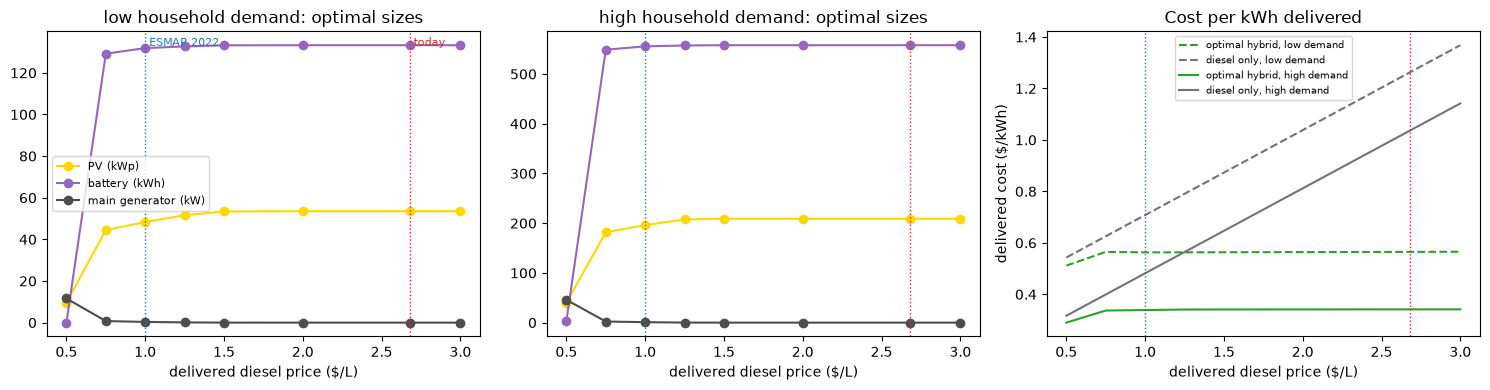

In [4]:
today, esmap = cst.diesel_usd_per_litre(), 1.00
fig, axs = plt.subplots(1, 3, figsize=(15, 4))
for ax, dem in zip(axs[:2], ("low", "high")):
    x = ds[ds.demand == dem].sort_values("price")
    ax.plot(x.price, x["PV kWp"], "o-", color="gold", label="PV (kWp)")
    ax.plot(x.price, x["battery kWh"], "o-", color="tab:purple", label="battery (kWh)")
    ax.plot(x.price, x["main diesel kW"], "o-", color="0.3", label="main generator (kW)")
    ax.set_title(f"{dem} household demand: optimal sizes"); ax.set_xlabel("delivered diesel price ($/L)")
for dem, style in (("low", "--"), ("high", "-")):
    x = ds[ds.demand == dem].sort_values("price"); y = dsl[dsl.demand == dem].sort_values("value")
    axs[2].plot(x.price, x["LCOE delivered $/kWh"], style, color="tab:green", label=f"optimal hybrid, {dem} demand")
    axs[2].plot(y.value, y["LCOE delivered $/kWh"], style, color="0.45", label=f"diesel only, {dem} demand")
axs[2].set_xlabel("delivered diesel price ($/L)"); axs[2].set_ylabel("delivered cost ($/kWh)"); axs[2].set_title("Cost per kWh delivered")
for ax in axs:
    ax.axvline(today, color="tab:red", ls=":", lw=1); ax.axvline(esmap, color="tab:blue", ls=":", lw=1)
axs[0].legend(fontsize=8); axs[2].legend(fontsize=7)
axs[0].text(today, axs[0].get_ylim()[1] * 0.95, " today", color="tab:red", fontsize=8)
axs[0].text(esmap, axs[0].get_ylim()[1] * 0.95, " ESMAP 2022", color="tab:blue", fontsize=8)
fig.tight_layout(); fig.savefig(FIG / "diesel_price_sweep.png", dpi=150)

In [5]:
def entry_price(dem):
    x = ds[(ds.demand == dem) & (ds["main diesel kW"] > 0.5)].sort_values("price")
    return x.price.max() if len(x) else None
pd.Series({dem: entry_price(dem) for dem in ("low", "high")}, name="highest diesel price ($/L) at which the optimum still builds a main generator").to_frame()

,highest diesel price ($/L) at which the optimum still builds a main generator
low,0.75
high,1.00


## 2. Equipment costs

In [6]:
cost_sweeps = res[res.sweep.isin(["battery $/kWh", "ESMAP component costs"])]
cost_sweeps.set_index(["sweep", "demand", "value"])[cols]

PV kWp  battery kWh  \
sweep                 demand value                                  
battery $/kWh         low    220               52.56       134.48   
                             314               53.54       133.28   
                             408               54.30       132.58   
ESMAP component costs low    25th percentile   53.30       133.34   
                             median            53.54       133.28   
                             75th percentile   54.12       133.18   
battery $/kWh         high   220              205.81       562.94   
                             314              208.93       558.00   
                             408              211.92       555.46   
ESMAP component costs high   25th percentile  207.54       558.34   
                             median           208.93       558.00   
                             75th percentile  212.22       557.58   

                                              main diesel kW  \
sweep                 demand value                             
battery $/kWh         low    220                         0.0   
                             314                         0.0   
                             408                         0.0   
ESMAP component costs low    25th percentile             0.0   
                             median                      0.0   
                             75th percentile             0.0   
battery $/kWh         high   220                         0.0   
                             314                         0.0   
                             408                         0.0   
ESMAP component costs high   25th percentile             0.0   
                             median                      0.0   
                             75th percentile             0.0   

                                              backup generator kW  \
sweep                 demand value                                  
battery $/kWh         low    220                              3.0   
                             314                              3.0   
                             408                              3.0   
ESMAP component costs low    25th percentile                  3.0   
                             median                           3.0   
                             75th percentile                  3.0   
battery $/kWh         high   220                              3.0   
                             314                              3.0   
                             408                              3.0   
ESMAP component costs high   25th percentile                  3.0   
                             median                           3.0   
                             75th percentile                  3.0   

                                              households unserved %  \
sweep                 demand value                                    
battery $/kWh         low    220                               4.56   
                             314                               4.57   
                             408                               4.58   
ESMAP component costs low    25th percentile                   4.57   
                             median                            4.57   
                             75th percentile                   4.56   
battery $/kWh         high   220                               4.90   
                             314                               4.90   
                             408                               4.90   
ESMAP component costs high   25th percentile                   4.90   
                             median                            4.90   
                             75th percentile                   4.90   

                                              hours with household shortfall  \
sweep                 demand value                                             
battery $/kWh         low    220                            

## 3. Reliability target

In [7]:
rel = res[res.sweep == "households unserved target %"]
rel.set_index(["demand", "value"])[cols]

PV kWp  battery kWh  main diesel kW  backup generator kW  \
demand value                                                             
low    0.0     60.97       134.68            2.37                  3.0   
       1.0     60.97       134.68            1.12                  3.0   
       5.0     53.54       133.28            0.00                  3.0   
high   0.0    251.53       563.56            9.89                  3.0   
       1.0    252.16       563.51            4.07                  3.0   
       5.0    208.93       558.00            0.00                  3.0   

              households unserved %  hours with household shortfall  \
demand value                                                          
low    0.0                     1.72                             236   
       1.0                     2.51                             289   
       5.0                     4.57                             515   
high   0.0                     1.47                             193   
       1.0                     2.19                             274   
       5.0                     4.90                             567   

              clinic/school hours cut  diesel litres/yr  LCOE delivered $/kWh  \
demand value                                                                    
low    0.0                          0            222.28                  0.57   
       1.0                          0            113.13                  0.57   
       5.0                          0             58.09                  0.57   
high   0.0                          0            871.08                  0.36   
       1.0                          0            392.06                  0.35   
       5.0                          0             61.02                  0.34   

              LCOE delivered N/kWh  
demand value                        
low    0.0                  797.22  
       1.0                  792.96  
       5.0                  786.40  
high   0.0                  499.08  
       1.0                  492.50  
       5.0                  475.42

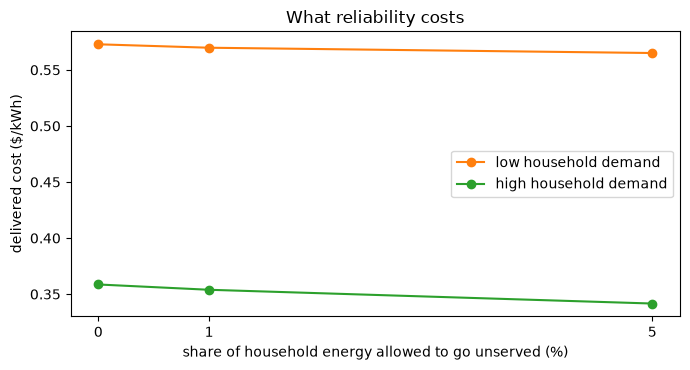

In [8]:
fig, ax = plt.subplots(figsize=(7, 3.8))
for dem, c in (("low", "tab:orange"), ("high", "tab:green")):
    x = rel[rel.demand == dem].assign(t=lambda y: y.value.astype(float)).sort_values("t")
    ax.plot(x.t, x["LCOE delivered $/kWh"], "o-", color=c, label=f"{dem} household demand")
ax.set_xlabel("share of household energy allowed to go unserved (%)"); ax.set_ylabel("delivered cost ($/kWh)")
ax.set_xticks([0, 1, 5]); ax.legend(); ax.set_title("What reliability costs")
fig.tight_layout(); fig.savefig(FIG / "reliability_cost.png", dpi=150)

Note: the 0 % and 1 % designs are sized by the optimiser with perfect foresight; run with the no-foresight rule they still leave some household energy unserved (column *households unserved %*).

## 4. Demand growth: size for today or for year 5?

In [9]:
res[res.sweep == "demand growth"].set_index(["demand", "value"])[cols]

PV kWp  battery kWh  main diesel kW  \
demand value                                                                 
low    sized for today, run in year 5   53.54       133.28             0.0   
       sized for year 5                 65.31       167.45             0.0   
high   sized for today, run in year 5  208.93       558.00             0.0   
       sized for year 5                264.06       709.58             0.0   

                                       backup generator kW  \
demand value                                                 
low    sized for today, run in year 5                  3.0   
       sized for year 5                                3.0   
high   sized for today, run in year 5                  3.0   
       sized for year 5                                3.0   

                                       households unserved %  \
demand value                                                   
low    sized for today, run in year 5                  19.45   
       sized for year 5                                 4.66   
high   sized for today, run in year 5                  21.30   
       sized for year 5                                 4.92   

                                       hours with household shortfall  \
demand value                                                            
low    sized for today, run in year 5                            2426   
       sized for year 5                                           535   
high   sized for today, run in year 5                            2661   
       sized for year 5                                           570   

                                       clinic/school hours cut  \
demand value                                                     
low    sized for today, run in year 5                        0   
       sized for year 5                                      0   
high   sized for today, run in year 5                        0   
       sized for year 5                                      0   

                                       diesel litres/yr  LCOE delivered $/kWh  \
demand value                                                                    
low    sized for today, run in year 5            469.40                  0.55   
       sized for year 5                           58.26                  0.51   
high   sized for today, run in year 5            451.95                  0.33   
       sized for year 5                           61.26                  0.33   

                                       LCOE delivered N/kWh  
demand value                                                 
low    sized for today, run in year 5                770.55  
       sized for year 5                              712.45  
high   sized for today, run in year 5                458.73  
       sized for year 5                              454.76

## 5. Everything at once (high household demand)

,input,low,high,low label,high label
0,diesel price,0.34,0.34,$0.75/L,$3.00/L
1,battery cost,0.29,0.39,-30 %,+30 %
2,ESMAP component costs,0.31,0.43,25th pct,75th pct
3,reliability target,0.34,0.36,5 % unserved,0 % unserved


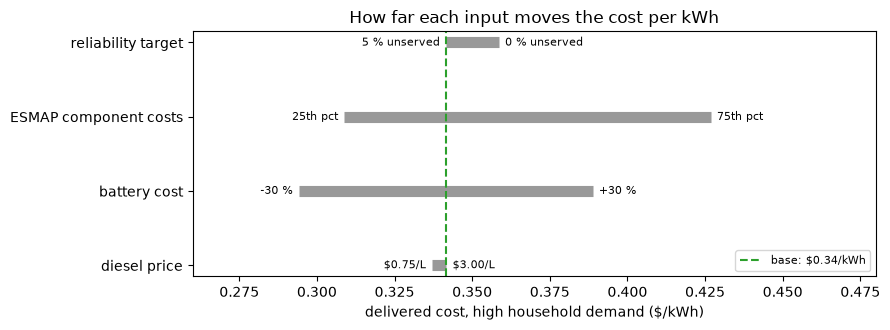

In [10]:
base = ds[(ds.demand == "high") & np.isclose(ds.price, round(today, 2))]["LCOE delivered $/kWh"].iloc[0]
rows = []
spec = [("diesel price", "diesel $/L", "0.75", "3.0", "$0.75/L", "$3.00/L"),
        ("battery cost", "battery $/kWh", None, None, "-30 %", "+30 %"),
        ("ESMAP component costs", "ESMAP component costs", "25th percentile", "75th percentile", "25th pct", "75th pct"),
        ("reliability target", "households unserved target %", "5.0", "0.0", "5 % unserved", "0 % unserved")]
for label, sweep, lo, hi, lo_txt, hi_txt in spec:
    x = res[(res.sweep == sweep) & (res.demand == "high")].set_index("value")["LCOE delivered $/kWh"]
    if lo is None:
        lo, hi = x.index[0], x.index[-1]
    rows.append({"input": label, "low": x[lo], "high": x[hi], "low label": lo_txt, "high label": hi_txt})
t = pd.DataFrame(rows)
fig, ax = plt.subplots(figsize=(9, 3.4))
for i, r in t.iterrows():
    a, b = sorted([r.low, r.high])
    ax.plot([a, b], [i, i], color="0.6", lw=8, solid_capstyle="butt")
    if b - a < 0.004:
        ax.text(b + 0.003, i, f"no change from {r['low label']} to {r['high label']}", va="center", fontsize=8)
    else:
        ax.text(a - 0.002, i, r["low label"] if r.low <= r.high else r["high label"], va="center", ha="right", fontsize=8)
        ax.text(b + 0.002, i, r["high label"] if r.low <= r.high else r["low label"], va="center", ha="left", fontsize=8)
ax.axvline(base, color="tab:green", ls="--", label=f"base: ${base:.2f}/kWh")
ax.set_yticks(range(len(t)), t.input); ax.set_xlim(0.26, 0.48)
ax.set_xlabel("delivered cost, high household demand ($/kWh)"); ax.legend(fontsize=8, loc="lower right")
ax.set_title("How far each input moves the cost per kWh")
fig.tight_layout(); fig.savefig(FIG / "sensitivity_range.png", dpi=150)
t

## What this shows

- **The design is insulated from the diesel price; diesel-only is not.** Above about $1.50 a litre the optimum builds no main generator at all, and its cost per kWh stays at about $0.34 (high demand) whatever diesel costs. Diesel only climbs from about $0.32 to $1.14 per kWh across the same range.
- **A main generator only makes sense with cheap diesel.** At $0.50 a litre the optimum is diesel-led (about 46 kW of generator with 40 kWp of PV, high demand). By $0.75 it is already mostly solar with a 2 kW generator, and at ESMAP's 2022 assumption of $1 a litre the generator is under 1 kW. RLI's design for this cluster (77 kW generator) therefore implies diesel at well under $1 a litre, or assumptions not in the dataset.
- **Equipment cost is the biggest uncertainty left.** Between ESMAP's 25th and 75th percentile costs the delivered cost ranges from about $0.31 to $0.43 per kWh (high demand), and from $0.53 to $0.65 (low demand). The battery price alone (plus or minus 30 %) moves it by about 5 US cents. The sizes barely change: the design is robust, the price is not.
- **Full reliability is cheap; foresight is not.** Asking the optimiser for 0 % or 1 % household shortfall instead of 5 % raises the cost per kWh by only about 2 US cents (high demand), adding PV and a small main generator. But run without foresight, even those designs leave households short about 1.5-2.5 % of their energy.
- **Size for growth.** A system sized for today, run with 5 years of 5 % yearly demand growth, leaves households short of about a fifth of their energy (2,400-2,700 hours a year). Sizing for year 5 (about 264 kWp and 710 kWh for high demand) keeps them at the 5 % target at about the same cost per kWh, because the extra energy sold pays for the extra equipment. A phased build (PV and battery added as demand grows) would be the practical version of that.

**Limits.** One typical weather year. Sweeps move one input at a time, apart from the ESMAP percentile sweep. Results are for the low clinic case; notebook 02 shows the clinic case changes little.
